# 数字1：直接法と提案法のCGH再生・伝搬比較

理論版と同じx–zシートを、圧縮コアのThread別重み付き加算→射影シフト→全コア加算→空間因子で復元する提案法で作ります。直接生成と同じ開口・CGH符号化・理想4f・伝搬を用い、**直接法との一致**と**数字1の目標との一致**を分けて確認します。

初期ランクは100。旧Stage Aの辞書は座標原点が異なるため、そのまま使用しません。専用辞書は初回に作り、同じ仕様なら次回以降は再利用します。実機のセンサー測定ではなく理想光学モデルです。詳細は `LSH数字1_提案法検証.md`。

修正版：中心ビームの偶成分だけに偏った基底を改め、Threadの正負の移動による奇成分もUxへ学習します。UyとUxは別々に保存します。旧v1画像の左右対称化の原因と修正内容は LSH数字1_左右対称化の修正.md。結果はshiftaware_v2へ保存します。


In [1]:
import importlib
from pathlib import Path
import json
from dataclasses import asdict
import lsh_digit1_theory as theory
import lsh_digit1_proposed as proposed
theory = importlib.reload(theory)
proposed = importlib.reload(proposed)

RANK = 100  # 共有空間因子のランク。ここを変更してください。
SEED = 42
BASIS_STRATEGY = 'shift_aware'  # 移動後の奇成分を含むx基底。旧結果は残します。
reference_results_dir = Path('lsh_digit1_theory_outputs_v1')
if (reference_results_dir / 'summary.json').is_file():
    config = proposed.config_from_theory_results(reference_results_dir)
    print('理論結果と同じ設定を使用:', reference_results_dir.resolve())
else:
    config = theory.Digit1Config()
    print('理論版の標準設定を使用')
# パディング比較を追加する場合：
# from dataclasses import replace
# config = replace(config, check_padding=True)

output_dir = Path(f'lsh_digit1_proposed_rank{RANK}_shiftaware_v2')  # 再計算する場合はv3等に変更
library_path = Path(f'lsh_digit1_library_rank{RANK}_shiftaware.npz')
RUN_SHIFT_DIAGNOSTICS = True  # 誤差の切り分け。オンライン時間には含めません。
print('ランク:', RANK, 'モード数/Thread:', theory.mode_design(config).count)
print('結果保存先:', output_dir.resolve())
print('圧縮辞書:', library_path.resolve())


理論結果と同じ設定を使用: C:\Users\kota-\Github\Project_new\research\lsh_digit1_theory_outputs_v1
ランク: 100 モード数/Thread: 15
結果保存先: C:\Users\kota-\Github\Project_new\research\lsh_digit1_proposed_rank100_shiftaware_v2
圧縮辞書: C:\Users\kota-\Github\Project_new\research\lsh_digit1_library_rank100_shiftaware.npz


In [2]:
expected_config = theory.config_payload(config)
summary_path = output_dir / 'summary.json'
if summary_path.is_file() and (output_dir / 'manifest.json').is_file():
    summary = json.loads(summary_path.read_text(encoding='utf-8'))
    if (summary.get('study') != 'digit1_direct_vs_projected_shared_core'
            or summary.get('schema_version') != proposed.SCHEMA_VERSION
            or summary.get('rank') != RANK or summary.get('seed') != SEED
            or summary.get('mode_spacing_factor', 1) != 1
            or summary.get('basis_strategy', 'center_only') != BASIS_STRATEGY
            or theory.config_payload(summary.get('config', {})) != expected_config
            or summary.get('library_path') != str(library_path.resolve())
            or (RUN_SHIFT_DIAGNOSTICS and summary.get('shift_diagnostics', {}).get('status') == 'not_run')):
        raise ValueError('保存結果と設定が異なります。output_dirを新しい名前に変更してください。')
    print('同じ条件の完了結果を読み込みました。')
elif output_dir.exists() and any(output_dir.iterdir()):
    raise ValueError('途中結果があります。output_dirを新しい名前に変更してください。')
else:
    summary = proposed.run_comparison(
        output_dir, config, rank=RANK, library_path=library_path, seed=SEED,
        run_shift_diagnostics=RUN_SHIFT_DIAGNOSTICS, basis_strategy=BASIS_STRATEGY)
print('結果:', output_dir.resolve())
print('実際のThread数:', summary['active_thread_count'])
print('非零Bessel項数:', summary['nonzero_bessel_term_count'])
print('CGH再生後：提案法 vs 直接法:', summary['metrics']['cgh_sheet_proposed_vs_direct'])
print('直接法CGH再生 vs 目標:', summary['metrics']['direct_cgh_sheet_vs_target'])
print('提案法CGH再生 vs 目標:', summary['metrics']['proposed_cgh_sheet_vs_target'])
print('符号化の振幅飽和割合:', {k: v['amplitude_saturation_fraction'] for k, v in summary['encoding'].items()})


Offline dictionary: mode 1/15
Offline dictionary: mode 2/15
Offline dictionary: mode 3/15
Offline dictionary: mode 4/15
Offline dictionary: mode 5/15
Offline dictionary: mode 6/15
Offline dictionary: mode 7/15
Offline dictionary: mode 8/15
Offline dictionary: mode 9/15
Offline dictionary: mode 10/15
Offline dictionary: mode 11/15
Offline dictionary: mode 12/15
Offline dictionary: mode 13/15
Offline dictionary: mode 14/15
Offline dictionary: mode 15/15
Offline: fit x basis including signed translations
Initial field: thread 5/21
Initial field: thread 6/21
Initial field: thread 7/21
Initial field: thread 8/21
Initial field: thread 9/21
Initial field: thread 10/21
Initial field: thread 11/21
Initial field: thread 12/21
Initial field: thread 13/21
Initial field: thread 14/21
Initial field: thread 15/21
Initial field: thread 16/21
Initial field: thread 17/21
Sensor propagation: 1/101, z=0.0 mm
Sensor propagation: 6/101, z=25.0 mm
Sensor propagation: 11/101, z=50.0 mm
Sensor propagation: 16/

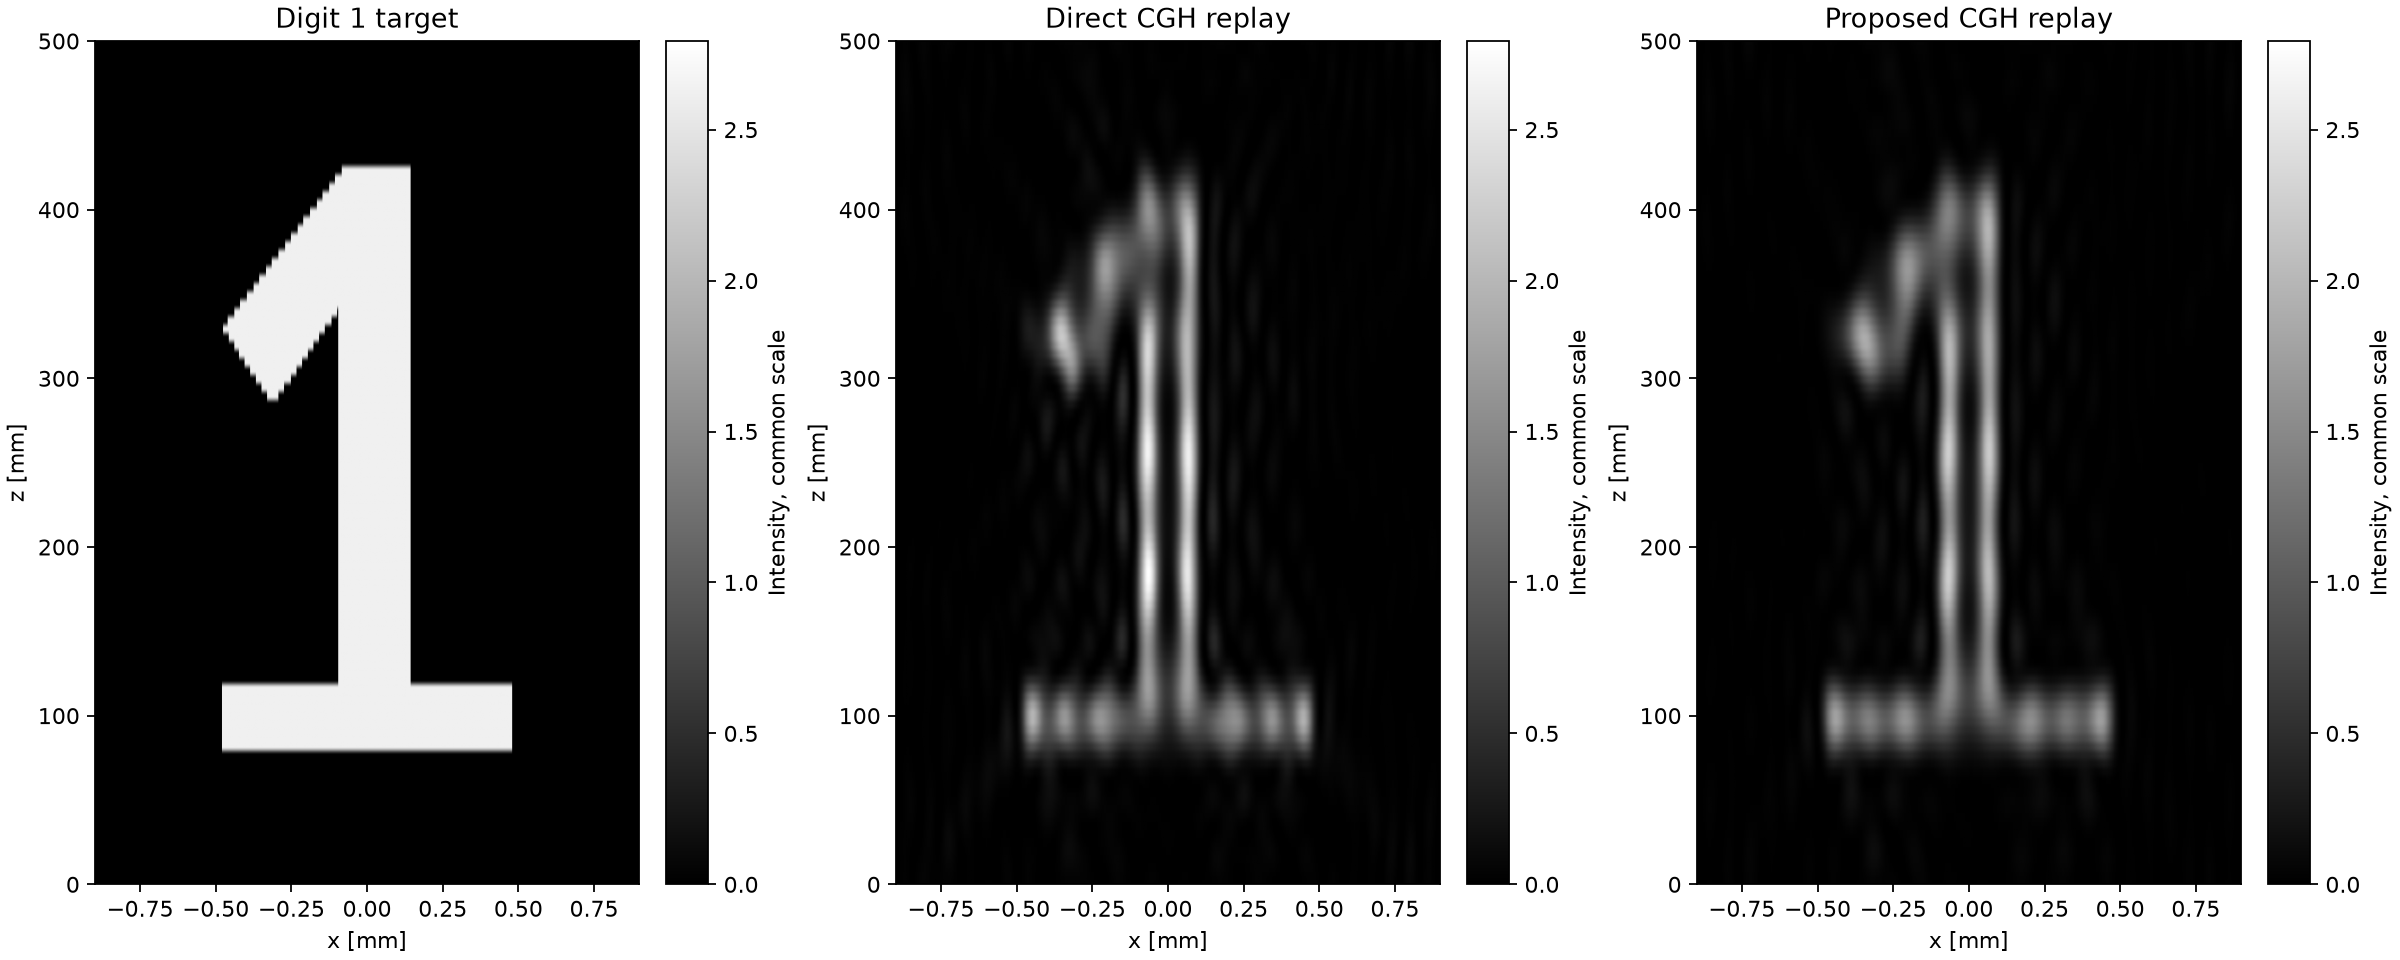

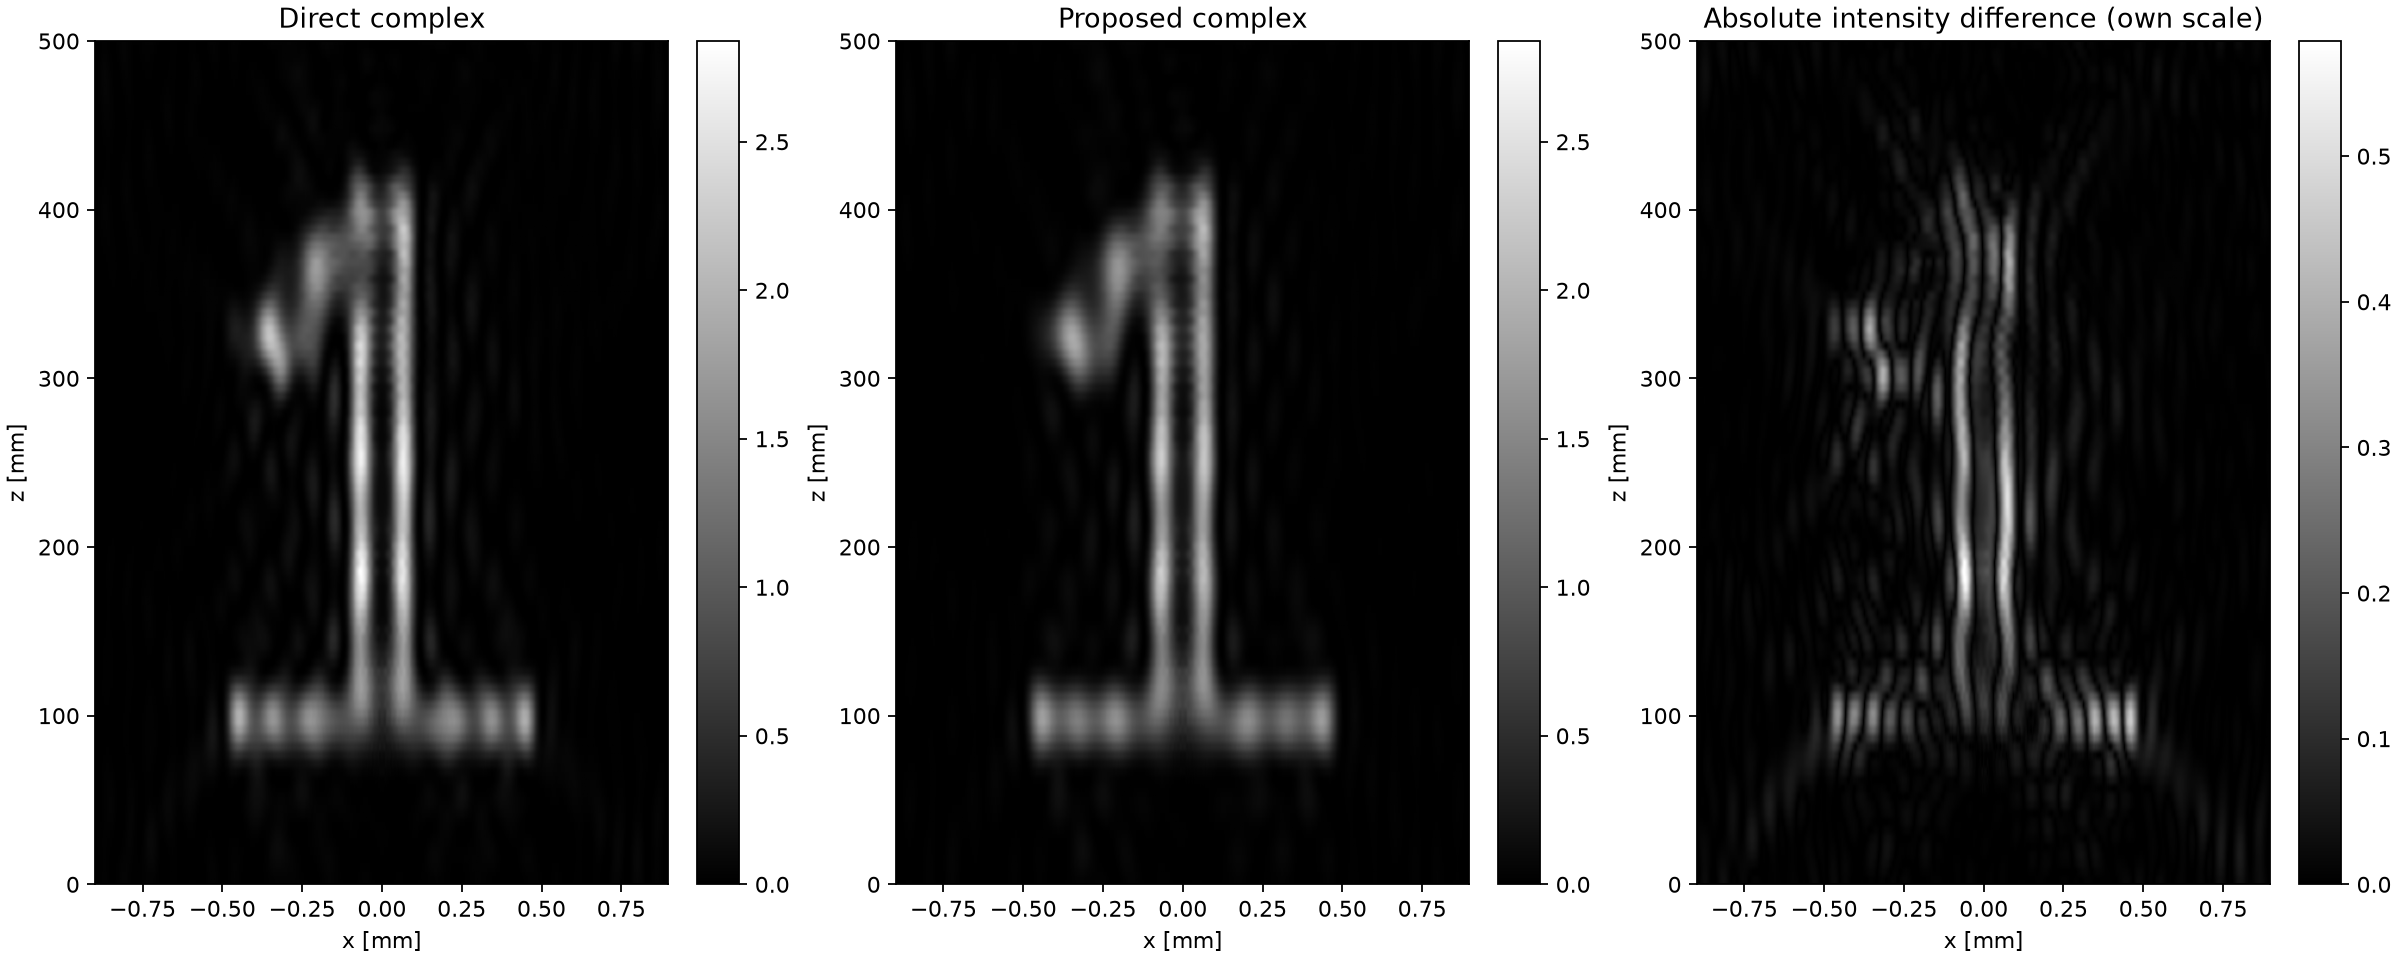

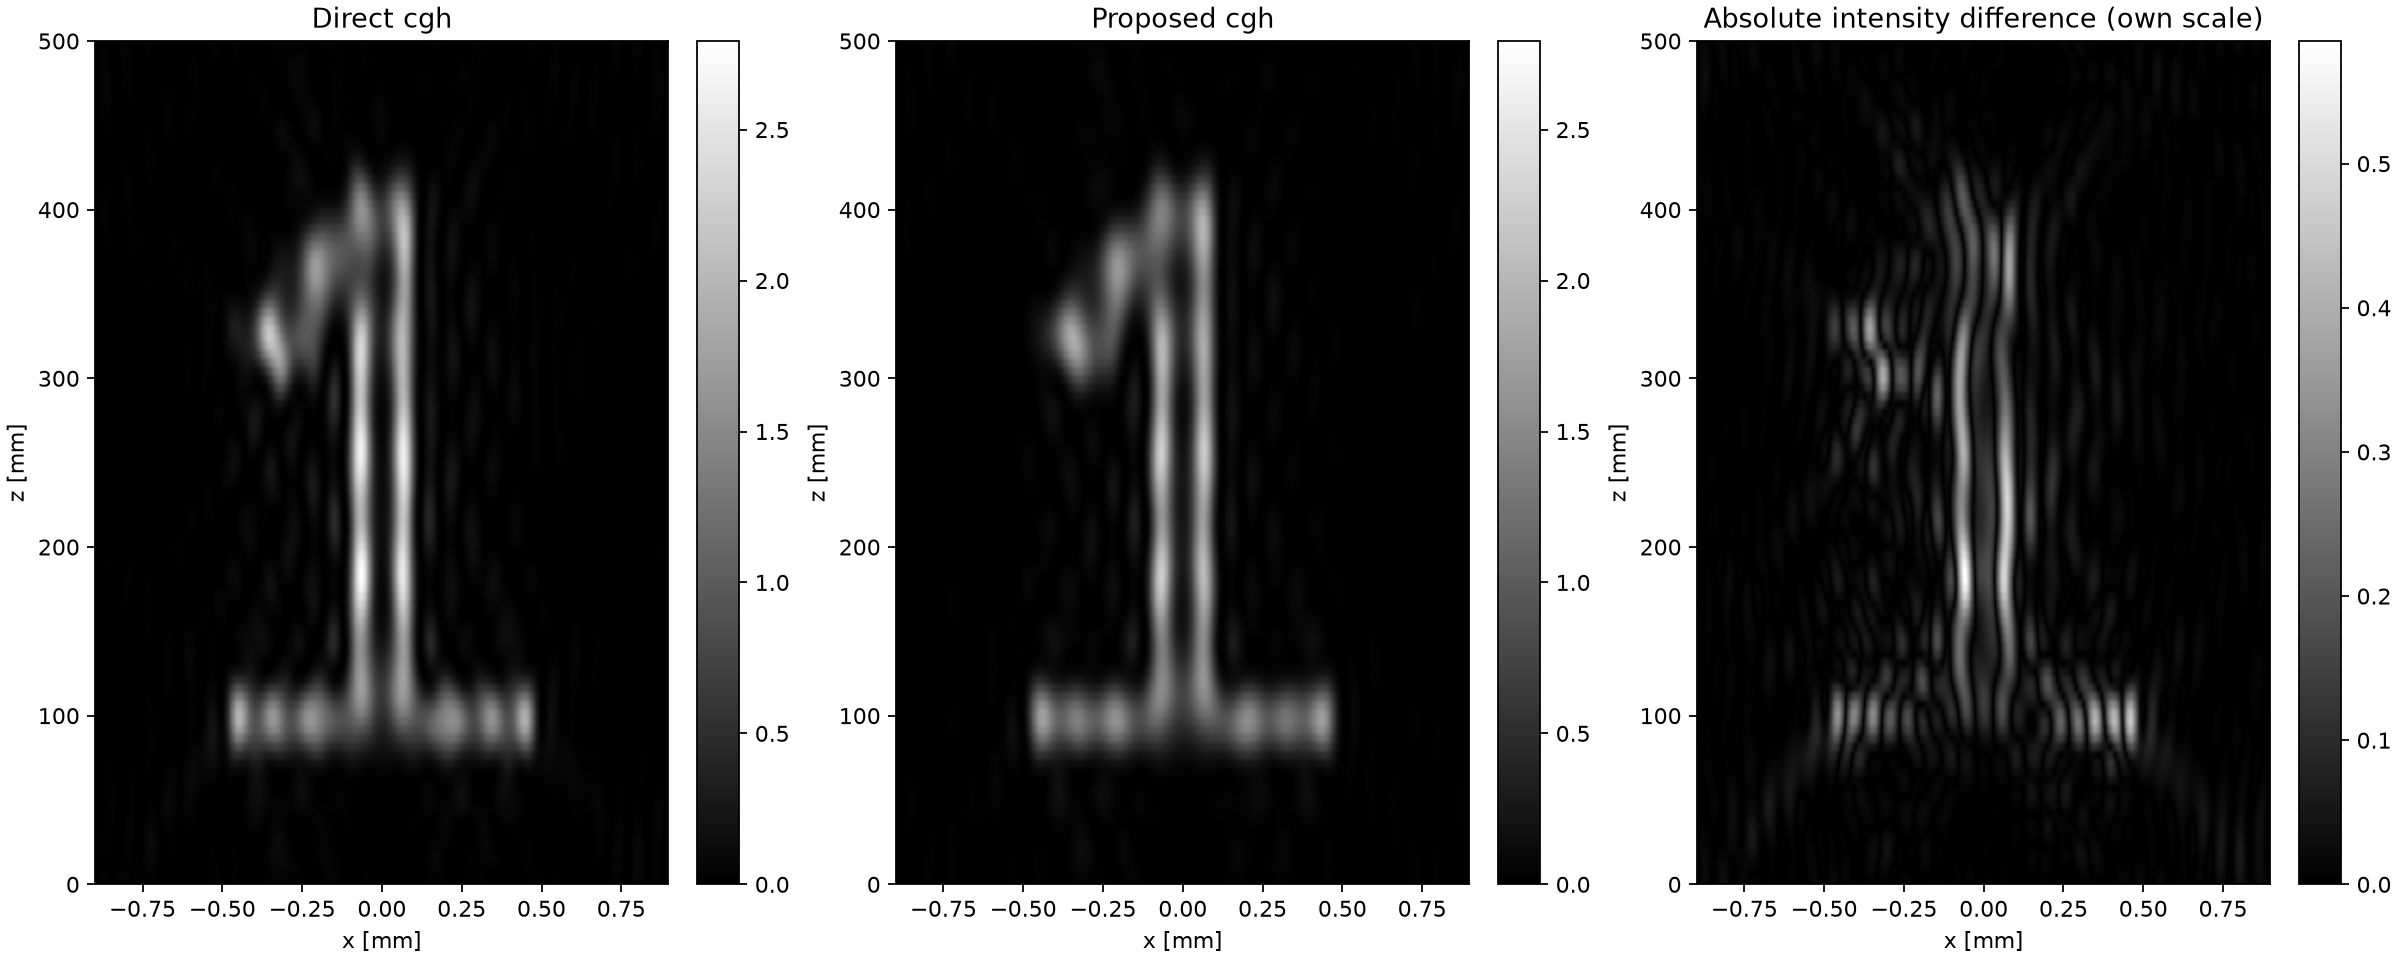

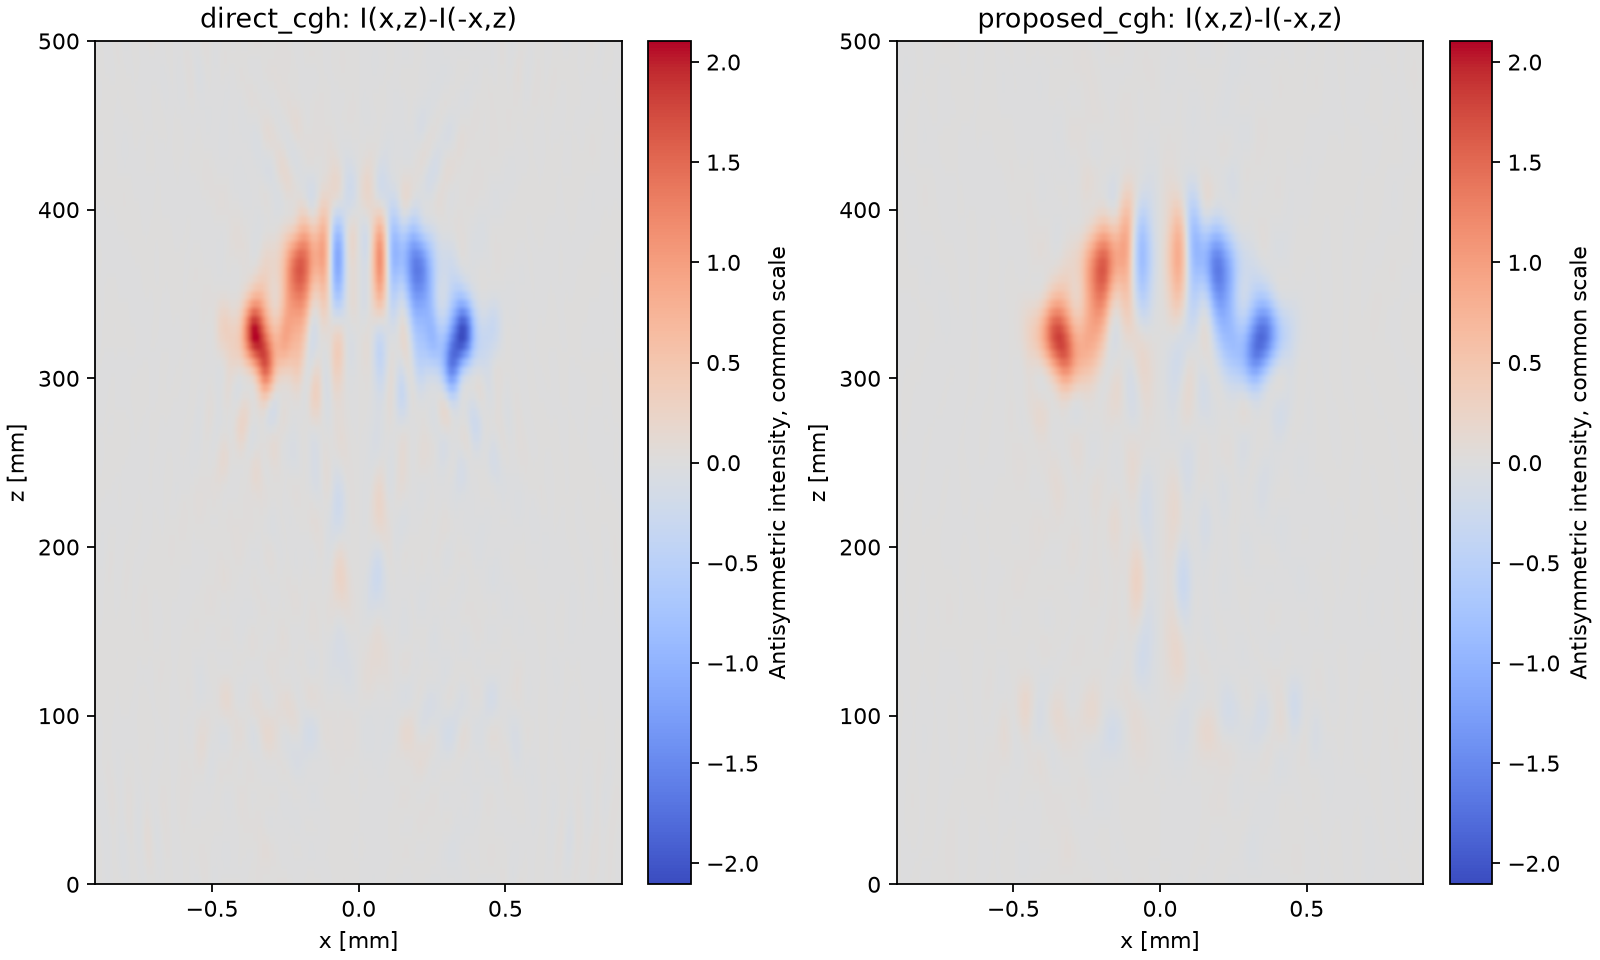

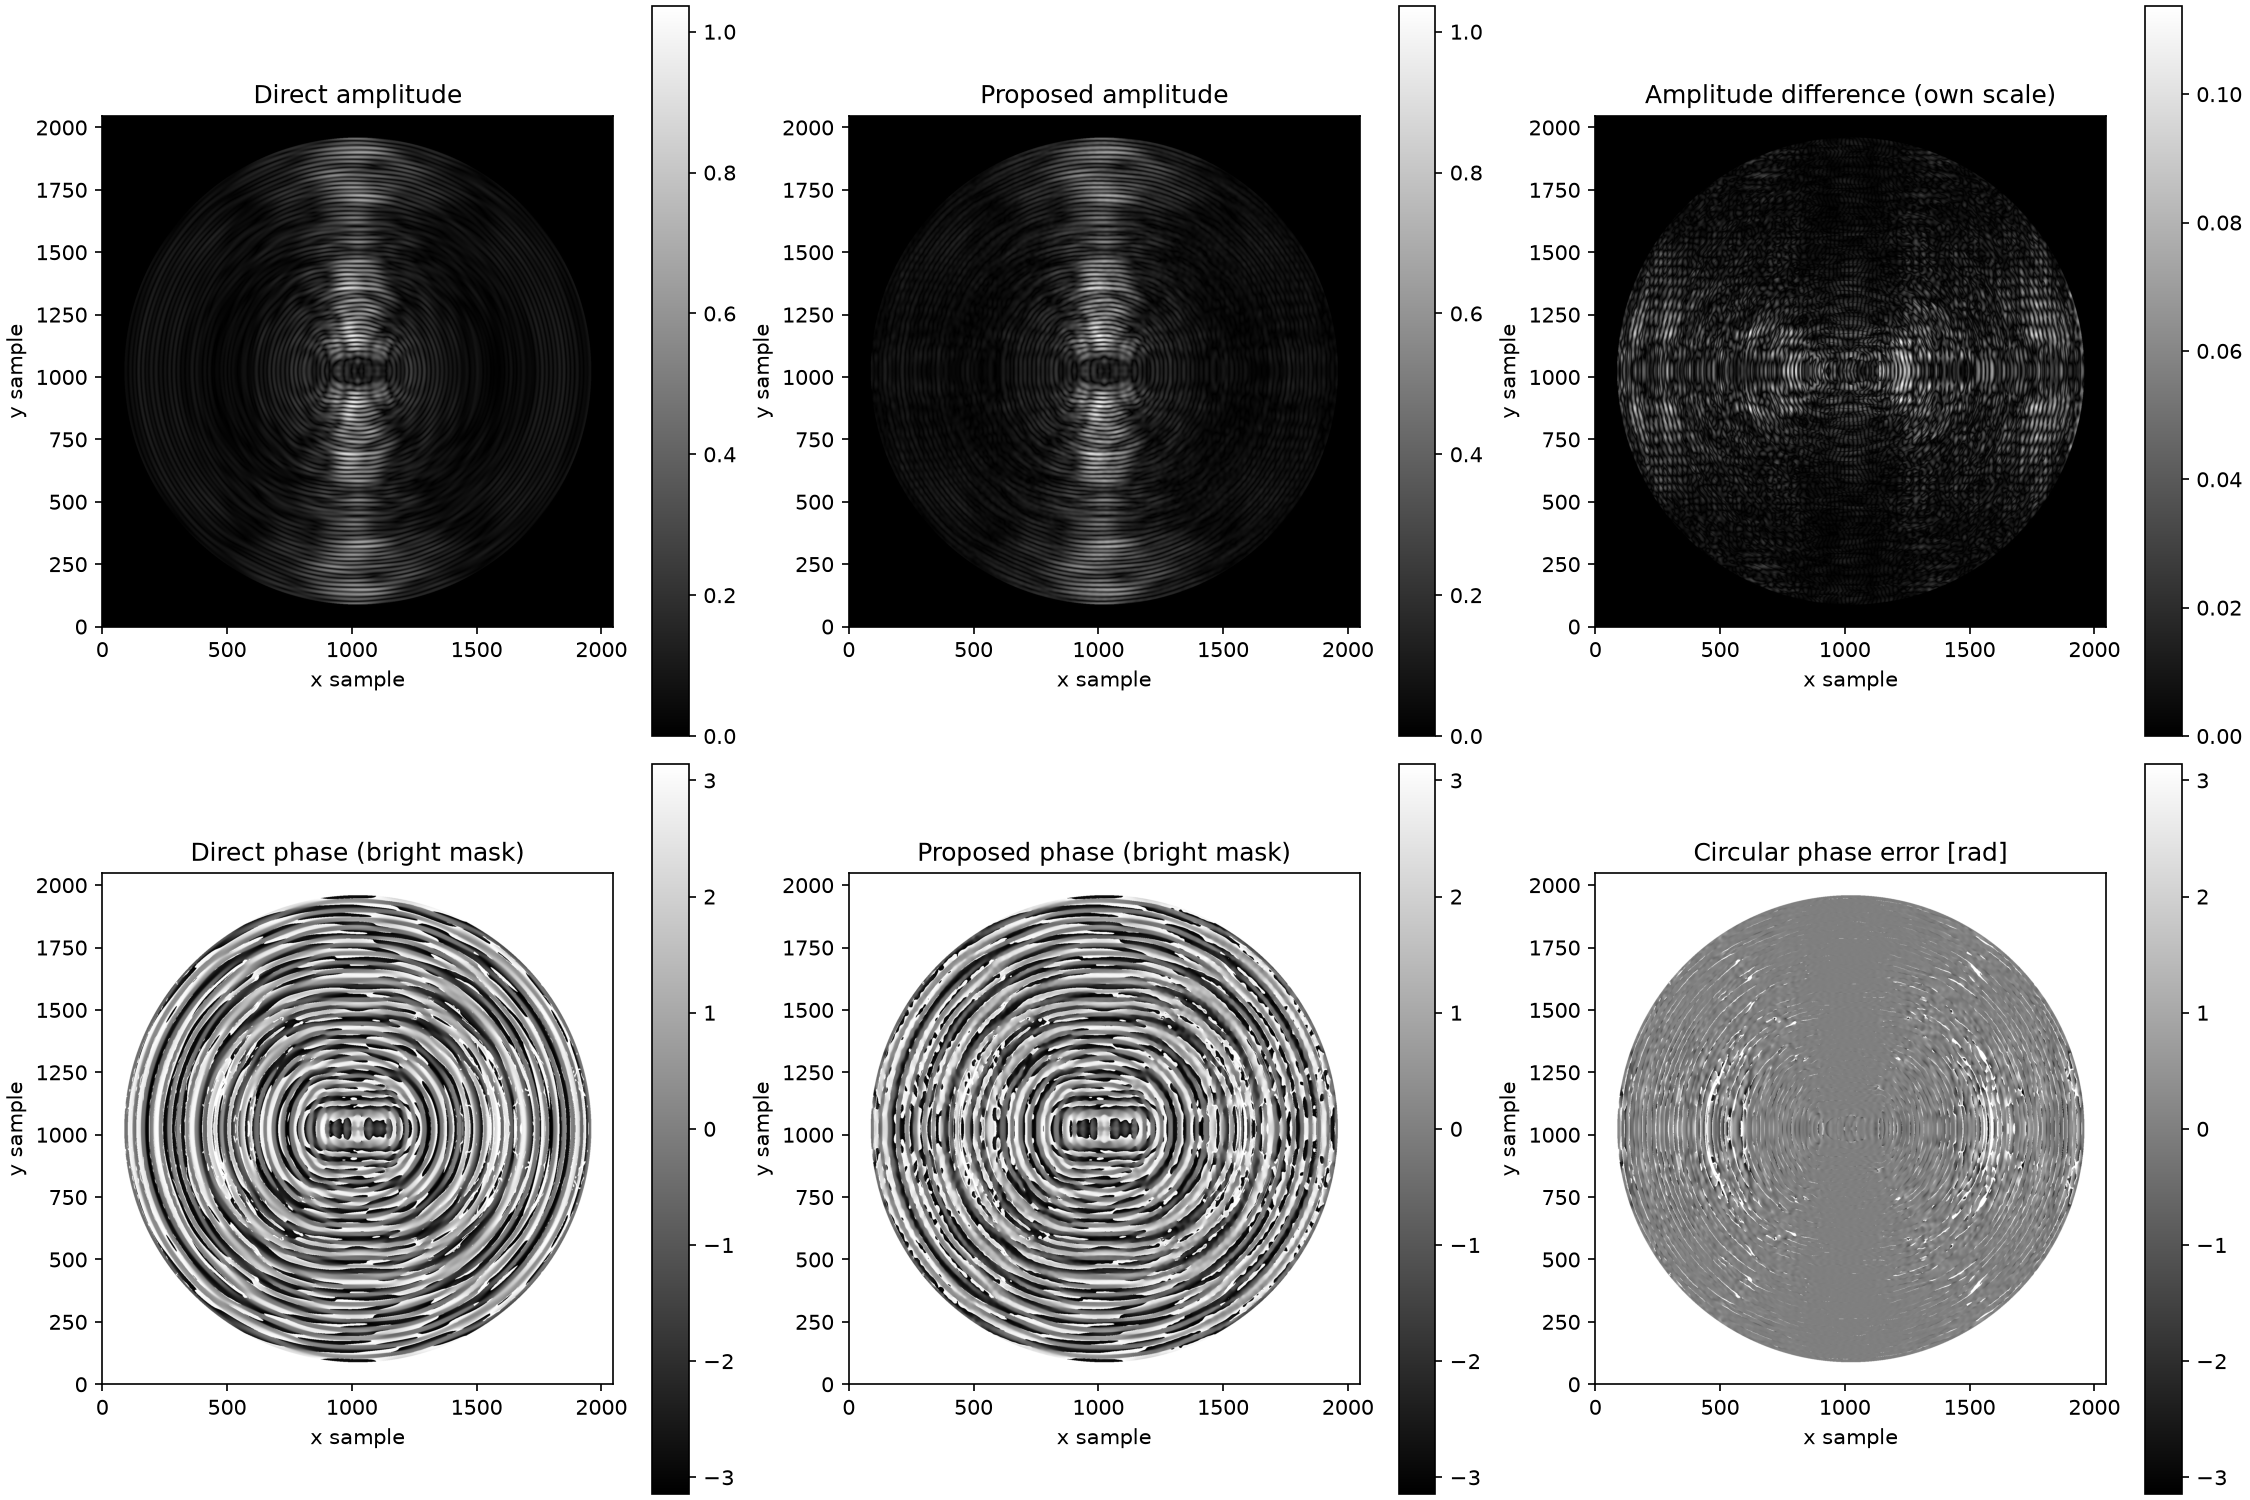

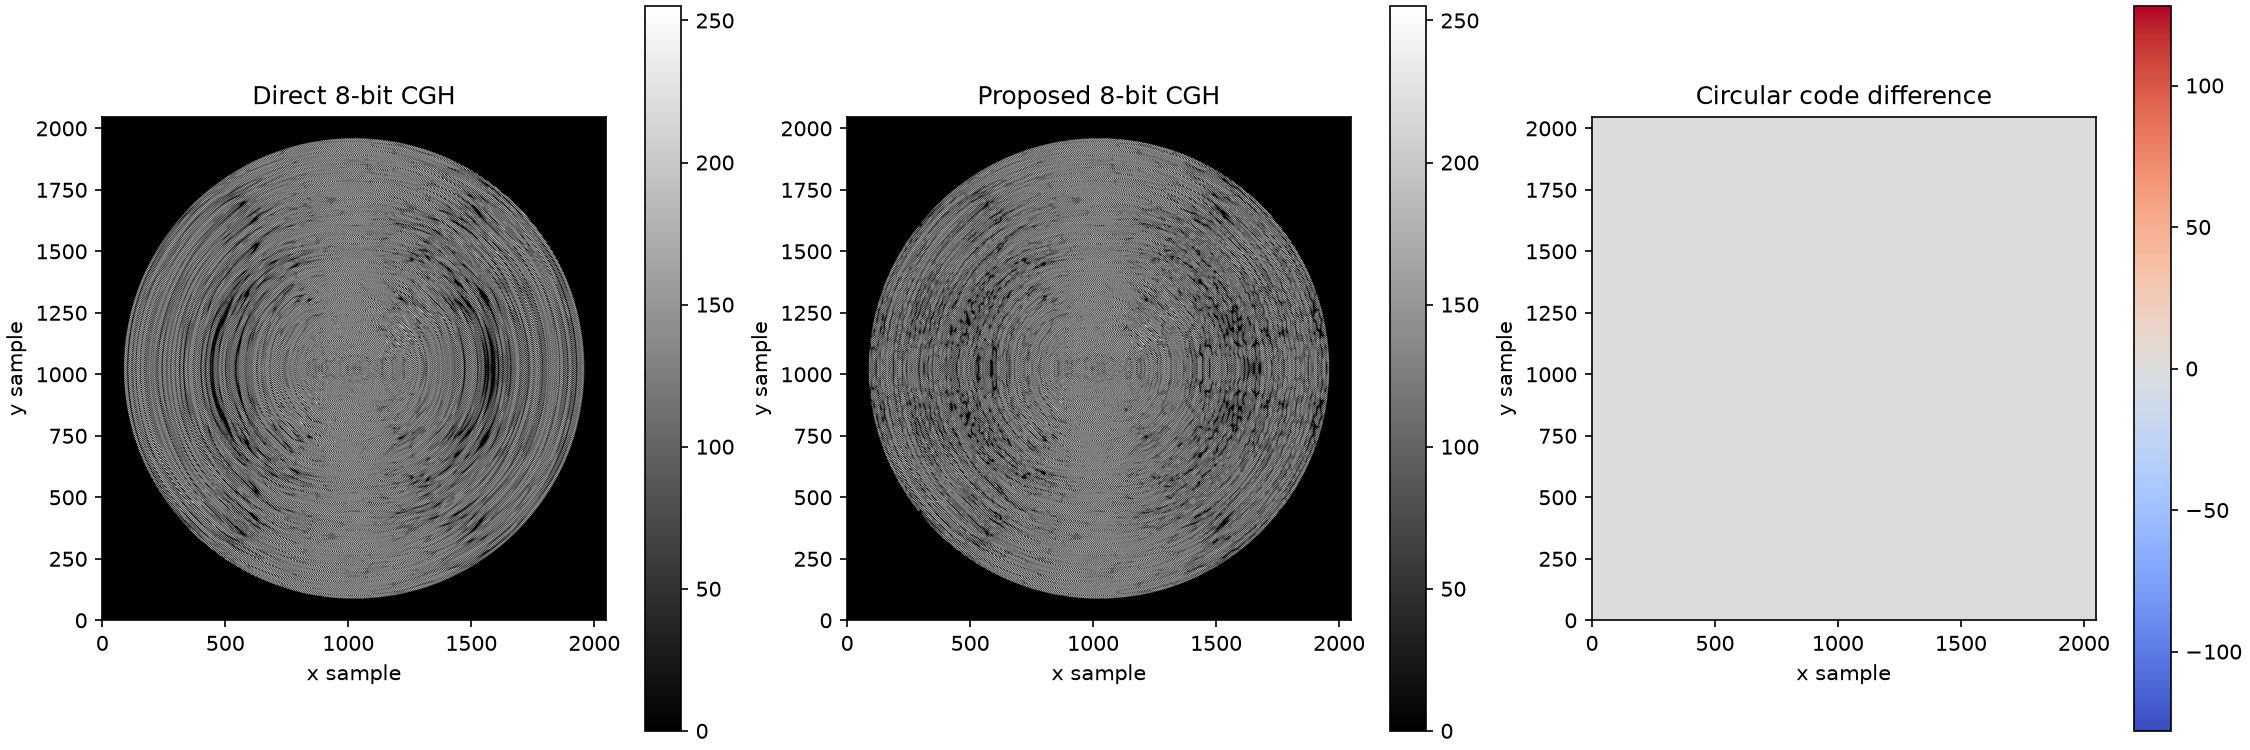

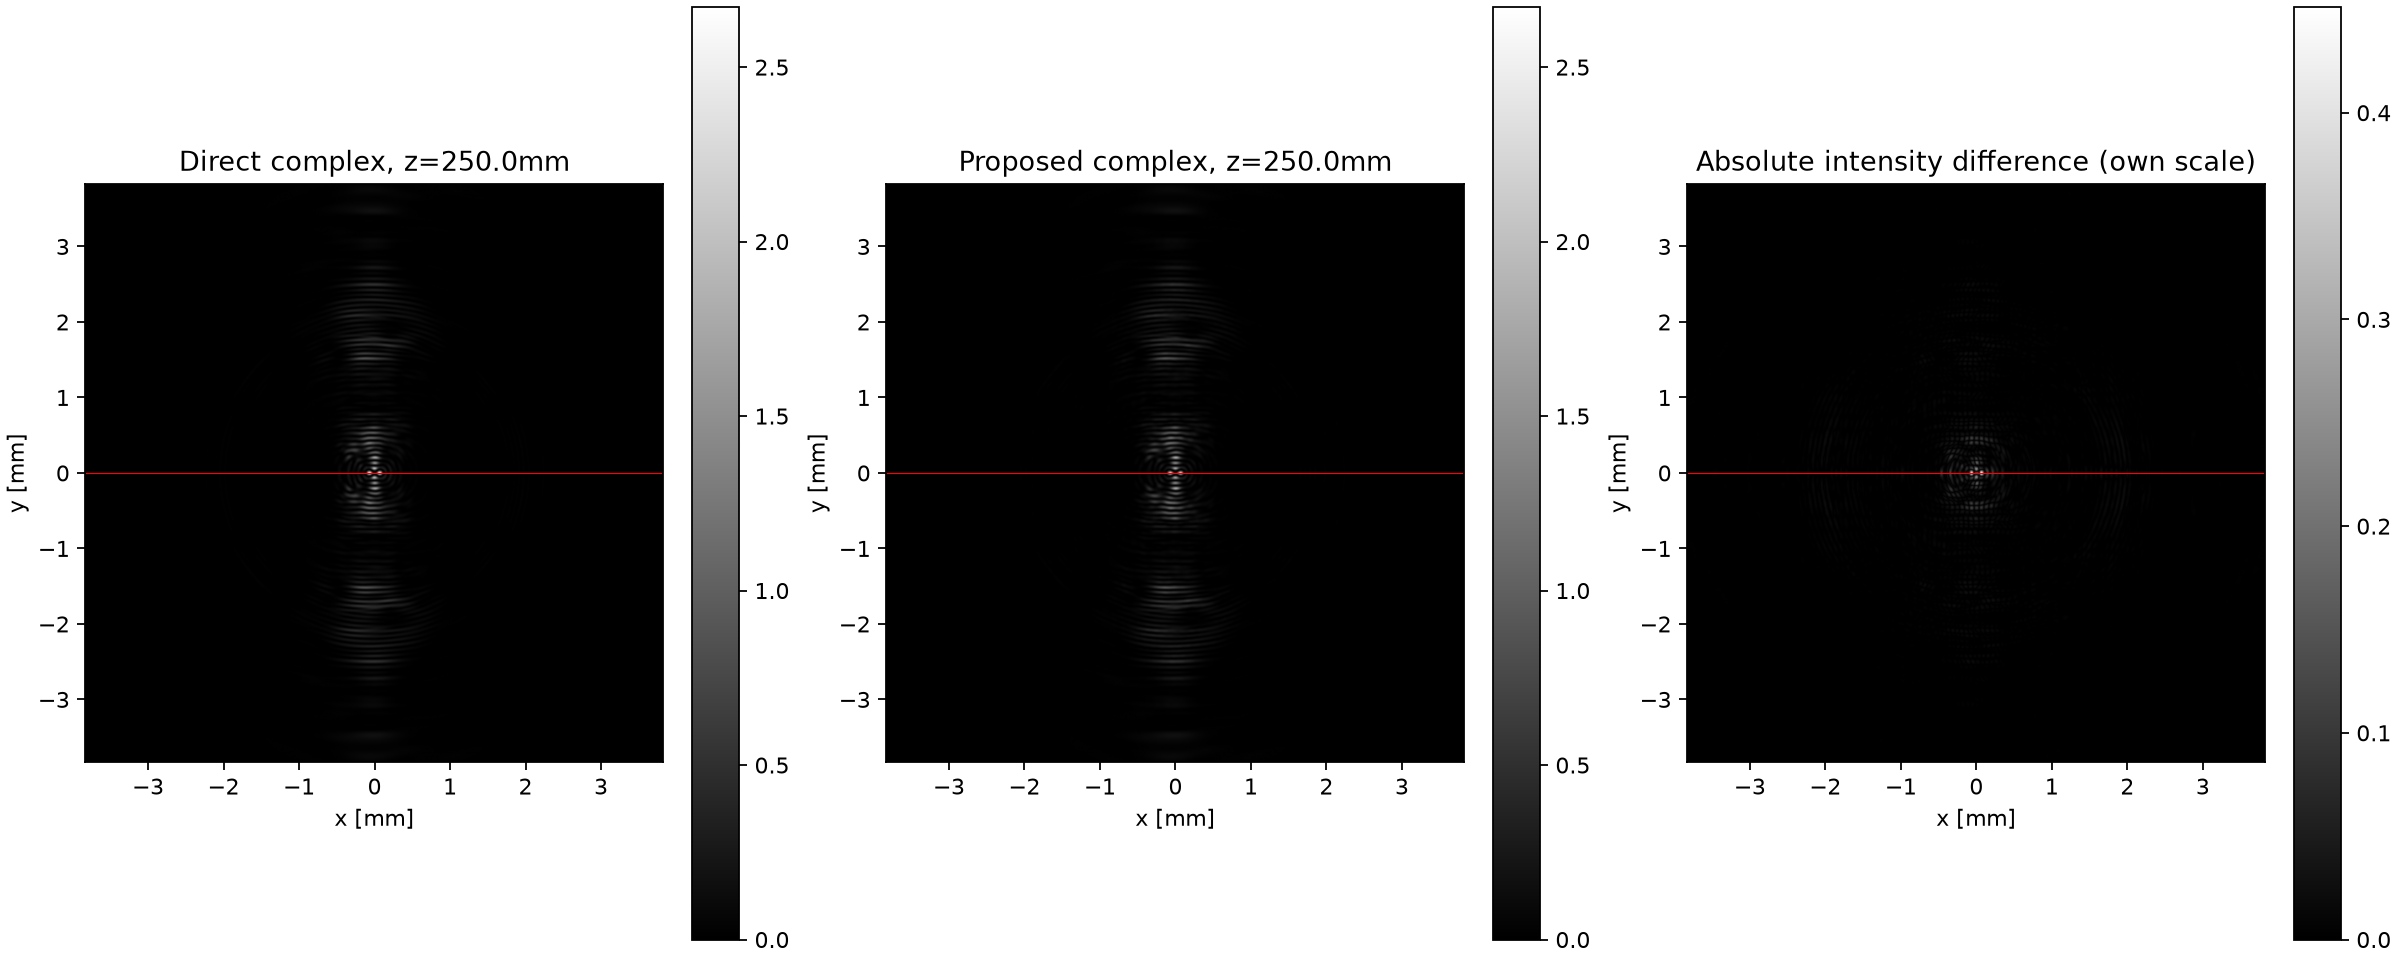

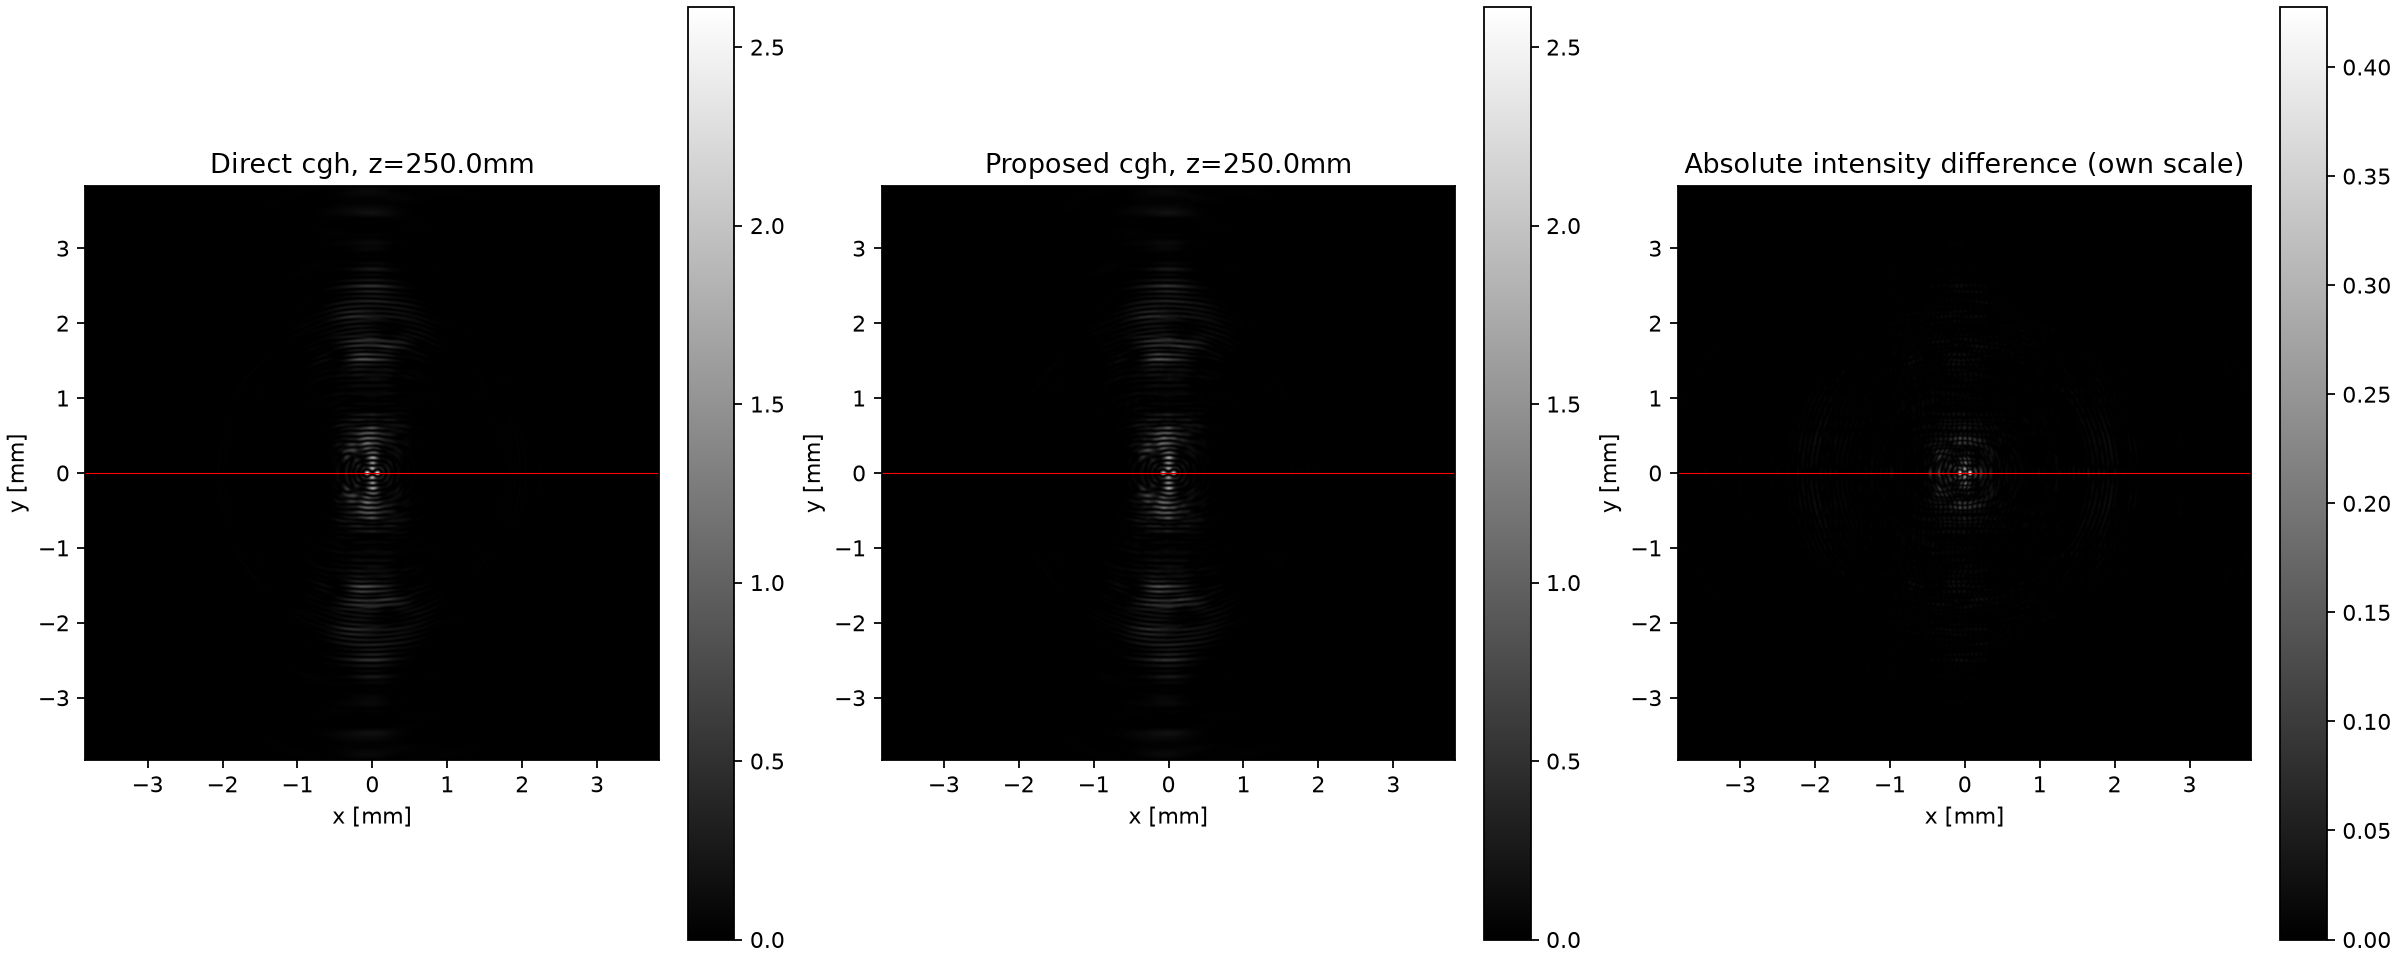

原寸CGH: C:\Users\kota-\Github\Project_new\research\lsh_digit1_proposed_rank100_shiftaware_v2\direct_cgh_8bit.png
原寸CGH: C:\Users\kota-\Github\Project_new\research\lsh_digit1_proposed_rank100_shiftaware_v2\proposed_cgh_8bit.png
因子行列: C:\Users\kota-\Github\Project_new\research\lsh_digit1_proposed_rank100_shiftaware_v2\factors


In [3]:
from IPython.display import Image, display
proposed.refresh_sheet_comparison_labels(output_dir)  # 保存強度から見出しを修正。伝搬は再計算しません。
for filename in ('target_direct_proposed.png', 'complex_sheet_comparison.png',
                 'cgh_sheet_comparison.png', 'asymmetry_comparison.png', 'initial_field_comparison.png', 'cgh_mask_comparison.png'):
    display(Image(filename=str(output_dir / filename), width=1200))
# センサーx–y強度。赤線y=0を抽出し、上のx–zシートを作ります。
for filename in ('complex_z0250.0mm.png', 'cgh_z0250.0mm.png'):
    sensor_image = output_dir / 'sensor_xy' / filename
    if sensor_image.is_file():
        display(Image(filename=str(sensor_image), width=1200))
print('原寸CGH:', (output_dir / 'direct_cgh_8bit.png').resolve())
print('原寸CGH:', (output_dir / 'proposed_cgh_8bit.png').resolve())
print('因子行列:', (output_dir / 'factors').resolve())


In [4]:
print('z=0 複素場の評価:', summary['metrics']['initial_complex_proposed_vs_direct'])
print('8-bit CGHの評価:', summary['metrics']['cgh_mask_proposed_vs_direct'])
print('シフト誤差の切り分け:', json.dumps(summary['shift_diagnostics'], indent=2, ensure_ascii=False))
print('オフライン:', summary['offline'])
print('時間[s]:', json.dumps(summary['timings_seconds'], indent=2, ensure_ascii=False))
print('時間の範囲:', summary['timing_scope'])
print('パディング検査:', summary['padding_check'])
print('左右対称性・符号付きシフト検査:', summary['symmetry_diagnostics'])
print('伝搬帯域制限:', summary['propagation_sampling'])
# 時間は1回の測定。数値の安定した速度比較は別途反復測定が必要です。


z=0 複素場の評価: {'complex_relative_l2': 0.15026597678661346, 'complex_snr_db': 16.4627871196218, 'amplitude_relative_l2': 0.11173615604639053, 'amplitude_ssim': 0.9501634800300075, 'amplitude_psnr_db': 36.97927769294498, 'amplitude_snr_db': 19.036056014234664, 'intensity_relative_l2': 0.06810498237609863, 'intensity_ssim': 0.9852461394270338, 'intensity_psnr_db': 48.68505304708708, 'intensity_snr_db': 23.336765347151246, 'bright_phase_mae_rad': 0.2365376204252243, 'bright_phase_rmse_rad': 0.4558447599411011, 'intensity_weighted_phase_mae_rad': 0.043578729033470154, 'phase_excluded_reference_energy_fraction': 0.0005956889363005757, 'phase_mask_pixel_fraction': 0.6417045593261719, 'bright_reference_dark_candidate_fraction': 0.017123140073356757}
8-bit CGHの評価: {'different_code_fraction_all_pixels': 0.29465413093566895, 'circular_code_mae_all_pixels': 0.3590102195739746, 'circular_phase_mae_all_pixels_rad': 0.00881143647169732, 'circular_phase_mae_bright_pixels_rad': 0.013404483827508123, 'raw